# Практика 3. Метод градиентного спуска

На этой практике мы рассмотрим как в действительности обучают линейную регрессию и познакомимся с методом градиентного спуска, который не отпустит нас на протяжении всего разговора о машинном обучении.

На самом деле линейную регрессию с точным аналитическим решением никто не использует. По простой причине: это долго. Аналитическое решение линейной регрессии находится по формуле: $$w=(X^\top X)^{-1}X^\top y.$$

Нам необходимо вычислить произведение $X^\top$ на $X$, что требует $O(d^2n)$ операций, используя самый простой алгоритмом. Также необходимо выполнять операцию обращения матрицы $(X^TX)$ размера $(d,d)$, где d $-$ это количество параметров модели (размерность вектора $w$). Время работы обращения матриц оценивается $O(d^3)$. 

Замечание о трудоёмкости нахождения аналитического решения справедливо в принципе для машинного обучения, во многих задачах и вовсе невозможно найти аналитическое решение и глобальный максимум правдоподобия.

Чаще всего применяют <b>метод градиентного спуска</b> с разными модификациями.

Метод градиентного спуска основан на минимизации <b>функции ошибки</b>. Функция ошибки - функция, минимизация которой приведёт к тому, что модель будет хорошо описывать данные. То есть, приведёт к максимизации правдоподобия. В нашем случае для линейной регрессии применяется <b>среднеквадратическая функция ошибки</b> (MSE Loss).

-------------

Пусть имеется обучающая выборка $D=\{(x_i,y_i)\}_{i=1}^n$.

Тогда среднеквадратическая функция ошибки в общем виде имеет следующий вид: $$MSELoss = \frac{1}{n}\sum_{i=1}^n(y_{i}-y_{i}')^2,$$
где $y_i'$ - предсказание модели, а в нашем случае $y_i'=x_iw$. Тогда функция ошибки для линейной регрессии обретает следующий вид: $$MSELoss = \frac{1}{n}\sum_{i=1}^n(y_{i}-w^Tx_i)^2.$$

Идея метода градиентного спуска:

- Вектор градиента функции потерь $\nabla L$ указывает направление и скорость наибольшего возрастания функции. Тогда вектор антиградиента будет указывать направление убывания функции.

- Давайте начнём в какой-то точке, к примеру сгенерируем из предполагаемого распределения весов. Далее будем совершать шаги по направлению антиградиента.

В виде формулы метод градиентного спуска записывается следующим образом:

$$w_j^{(t+1)}=w_j^{(t)}-\alpha\frac{\partial}{\partial w_j}L(X,y,w^{(t)}),$$

или в векторном виде:

$$w^{(t+1)}=w^{(t)}-\alpha\nabla_wL(w^{(t)}).$$

Для одномерного параметра это градиентный спуск можно проиллюстрировать следующим образом:

<img style="width: 50%; max-width: 960px; display: block; margin: 0 auto;" src="https://i.postimg.cc/dVqyLcRZ/grad-step-example.webp"/>

$w_j^{(t+1)}$ - новое значение параметра.

$w_j^{(t)}$ - старое значение параметра.

$\alpha$ - гиперпараметр (параметр алгоритма оптимизации), называемый <b>"темпом обучения"</b>. Отвечает за величину шага в направлении антиградиента. 

$L$ - MSE Loss или среднеквадратическая функция ошибки. Запишем её в матричном виде: $$L(X,y,w)=\frac{1}{n}||Xw-y||^2$$

Посчитаем градиент:

$$\nabla_wL=\frac{2}{n}X^T(Xw-y)$$

<b>Опишем алгоритм:</b>

0. Начальная инициализация параметров: $w^{(0)}$.
1. Считаем функцию ошибки: $L(X,y,w^{(t)})$.
2. Вычисляем гардиент: $\nabla_w L(X,y,w^{(t)})$.
3. Меняем параметры модели: $w^{(t+1)}=w^{(t)}-\alpha\nabla L_w(X,y,w^{(t)})$.
4. Переходим к шагу 1.

Можно заметить, что в алгоритме не описан критерий остановки.

Поэтому ограничим количество повторений цикла гиперпараметром, называемым количеством <b>эпох</b>. 

## Выбор гиперпараметров обучения

Параметр количества эпох должен быть выбран достаточно большим, чтобы "дойти" до точки минимума. А вот с темпом обучения сложнее:

<img style="width: 50%; max-width: 960px; display: block; margin: 0 auto;"  src="https://i.postimg.cc/DZH432JK/LR-example.png" width=800>


- Если темп обучения слишком низкий, то потребуется слишком много шагов, чтобы попасть в минимум. 
- Если темп обучения слишком высокий, то сходимость к минимуму может оказаться очень нестабильной. А иногда в минимум можно вовсе не попасть.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(0)  # для воспроизводимости

In [2]:
# Функция для отображения функции потери и спуска к оптимуму
def draw_descent(X, Y, w_true, w_list):
    radius = 3
    
    A, B = np.meshgrid(np.linspace(w_true[0] - radius, w_true[0] + radius, 200),
                       np.linspace(w_true[1] - radius,w_true[1] + radius, 200))

    W = np.vstack([A.ravel(),B.ravel()])
    
    levels = np.mean(np.power(np.dot(X, W) - Y, 2), axis=0).reshape(A.shape)
    
    plt.figure(figsize=(13, 9))
    plt.title('GD trajectory')
    plt.xlabel('$w_1$')
    plt.ylabel('$w_2$')
    wmin, wmax = w_list[:, 0].min(), w_list[:, 0].max()
    centr_x = (wmin + wmax) / 2
    width_x = np.abs(wmin - wmax)
    wmin, wmax = w_list[:, 1].min(),w_list[:, 1].max()
    centr_y = (wmin + wmax) / 2
    width_y = np.abs(wmin - wmax)
    width = np.max([width_x, width_y]) / 2 * 1.1
    plt.xlim(centr_x - width, centr_x + width)
    plt.ylim(centr_y - width, centr_y + width)
    plt.gca().set_aspect('equal')

    # visualize the level set
    CS = plt.contour(A, B, levels, levels=np.logspace(0, 2, num=100), cmap=plt.cm.rainbow_r)
    CB = plt.colorbar(CS, shrink=0.8, extend='both')

    # visualize trajectory
    plt.scatter(w_true[0], w_true[1], c='r')
    plt.scatter(w_list[:, 0], w_list[:, 1], zorder=100)
    plt.plot(w_list[:, 0], w_list[:, 1])

    plt.show()

Численное решение: [1.66693167 0.4035267 ]
Аналитическое решение: [1.66982582 0.40354431]
Истинное значение: [1.76405235 0.40015721]


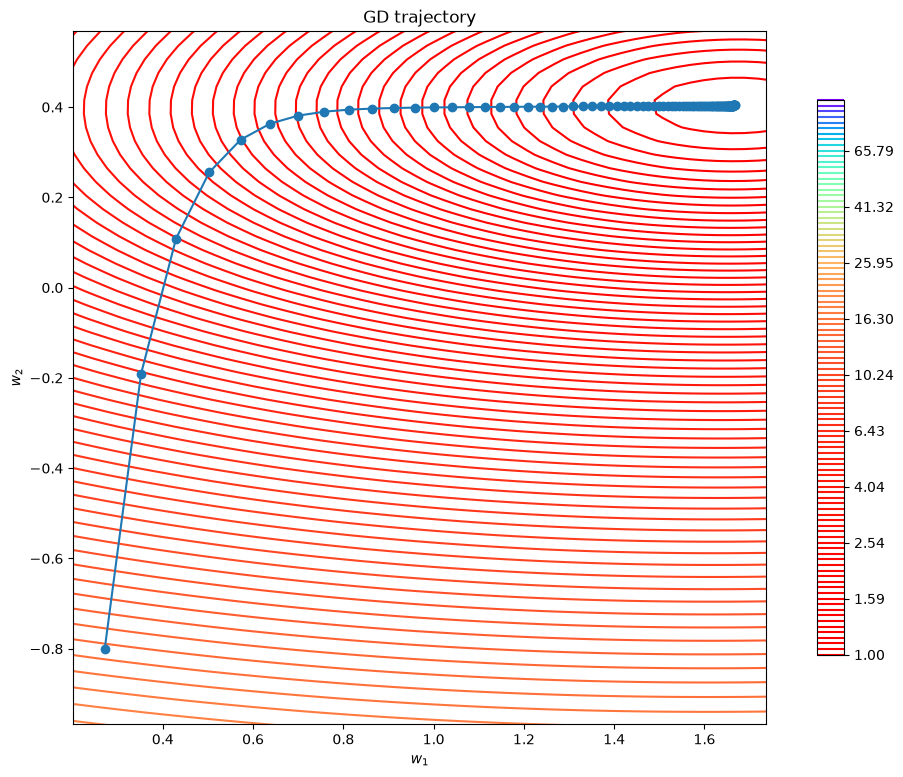

In [3]:
learning_rate = 0.03 # темп обучения
epochs = 100 # количество эпох обучения

n_dim = 2 # степень полинома
w_true = np.random.normal(0, 1, (n_dim, 1)) # настоящие параметры модели
# генерируем выборку
num_samples = 500  # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 100
x = np.hstack([np.ones((num_samples, 1)),
        np.random.uniform(-5, 5, (num_samples, n_dim - 1))])
    
y = x @ w_true + np.random.normal(0, sigma, (num_samples, 1))

w = np.random.normal(0, 1, (n_dim, 1))
w_list = [w.copy()]

for i in range(0,epochs):
    # Вычислите градиент
    grad = 2 / num_samples * x.T @ (x @ w - y)
    # Измените параметры модели
    w = w - learning_rate * grad
    # Сохраняем веса в список
    w_list.append(w.copy())

w_exact = (np.linalg.inv(x.T @ x) @ x.T @ y)
print(f"Численное решение: {w.ravel()}")
print(f"Аналитическое решение: {w_exact.ravel()}")
print(f"Истинное значение: {w_true.ravel()}")
draw_descent(x, y, w_true, np.array(w_list))

## Метод Ньютона

Что будет, если признаки X будут иметь разный масштаб? Тогда эллиптический параболоид, возникающий из среднеквадратический функции ошибки будет сплюснут по одной из координат. И в этот момент возникает проблема с параметром темпа обучения. 

Из-за того, что параметр темпа обучения одинаков для всех параметров $w_i$, то окажется, что по одной координате шаг может быть слишком большим, а по другой координате - слишком маленьким. 

В примере ниже, где соотношение "сторон" чуть менее 2-х, оказывается, что по одной координате ($w_1$) темп обучения вполне подходящий, а по другой ($w_2$) - слишком высокий. И в итоге градиентный спуск расходится. 

А разность масштаба признаков сплошь и всюду. К примеру, мы по росту (в см.) и весу(в кг.) хотим предсказать возраст человека. Скорее всего вес человека раза в 2-3 меньше роста человека и уже может возникнуть проблемы. А если добавить в модель признак "зароботок"(в рублях), то проблемы уже точно гарантированы.

Простым уменьшением темпа обучения эту проблему не решить. Можно увеличить кривизну параболоида и добиться ситуации, когда по одной координате градиентный спуск будет расходится, а по другой потребует слишком много итераций, чтобы достигнуть минимума. А в случае, если признаков не 2, а 100, найти оптимальный темп обучения может быть затруднительно.

Численное решение: [-0.31257699 -0.79178541]
Аналитическое решение: [-0.28911866  0.11443867]
Истинное значение: [-0.29050317  0.11212805]


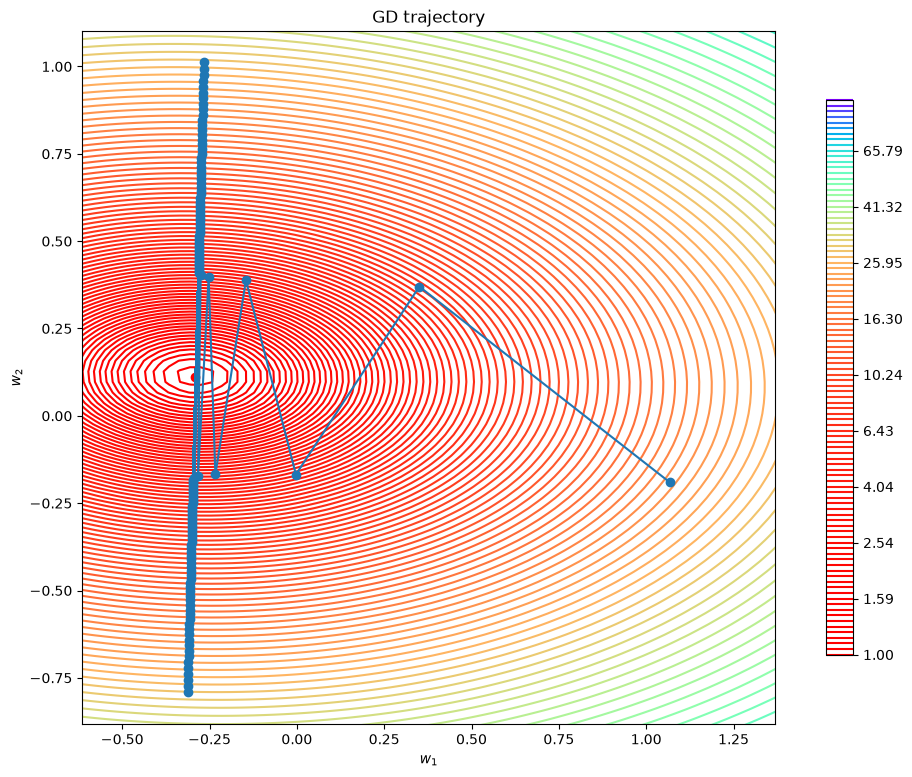

In [4]:
learning_rate = 0.03 # темп обучения
epochs = 120 # количество эпох обучения
np.random.seed(51)

n_dim = 2 # степень полинома
w_true = np.random.normal(0, 1, size=(n_dim, 1)) # настоящие параметры модели

# генерируем выборку
num_samples = 500  # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 100
x = np.concatenate([np.random.normal(0, 3, (num_samples, n_dim-1)),
                    np.random.normal(0, 5.85, (num_samples, 1))],axis=1)

y = x @ w_true + np.random.normal(0, sigma, (num_samples, 1))

w = np.random.normal(0, 1,size=(n_dim,1))
w_list = [w.copy()]

for i in range(0,epochs):
    # Вычислите градиент
    grad = 2 / num_samples * x.T @ (x @ w - y)
    # Измените параметры модели
    w = w - learning_rate * grad
    # Сохраняем веса в список
    w_list.append(w.copy())

w_exact = (np.linalg.inv(x.T @ x) @ x.T @ y)
print(f"Численное решение: {w.ravel()}")
print(f"Аналитическое решение: {w_exact.ravel()}")
print(f"Истинное значение: {w_true.ravel()}")
draw_descent(x, y, w_true, np.array(w_list))

Одним решением может быть приведение величин к одному масштабу. К примеру, можно вычесть среднее  и поделить на стандартное отклонение. И так правда часто делают, но в некоторых случаях это может быть не уместно. Иногда такую операцию нельзя делать из соображений о смысле переменных. 

Решение данной проблемы состоит в применении <b>метода Ньютона</b>, основанного на второй производной. Он позволит "выбрать" величину градиентного шага по каждому направлению отдельно.

Для этого необходимо разложить функцию ошибки в ряд Тейлора до второго члена:

$$L(w) \approx L(w^{(t)})+\nabla_w L(w^{(t)})^T(w-w^{(t)})+\frac{1}{2}(w-w^{(t)})^TH_t(w-w^{(t)}),$$

$$H_k=\nabla_w^2L(w^{(t)})=\begin{pmatrix}
\frac{\partial^2L(w^{(t)})}{\partial w_1^2} & \frac{\partial^2L(w^{(t)})}{\partial w_1 \partial w_2} & \dots & \frac{\partial^2L(w^{(t)})}{\partial w_1 \partial w_d}\\
\frac{\partial^2L(w^{(t)})}{\partial w_2 \partial w_1} & \frac{\partial^2L(w^{(t)})}{\partial w_2^2} & \dots & \frac{\partial^2L(w^{(t)})}{\partial w_1 \partial w_d}\\
\vdots & \vdots & \ddots & \vdots\\
\frac{\partial^2L(w^{(t)})}{\partial w_d \partial w_1} & \frac{\partial^2L(w^{(t)})}{\partial w_d \partial w_2} & \dots & \frac{\partial^2L(w^{(t)})}{\partial w_d^2}\\
\end{pmatrix}.$$

$H_k$ называют Гессианом, это матрица вторых производных.

Далее вычислим градиент по $w$. Необходимо расписать $w=(w_1,\dots,w_d)$ и посчитать частные производные $\frac{\partial}{\partial w_i}$. Мы это опустим, а вы <b>сделаете это дома</b> в качестве упражнения. Результат:

$$\nabla_w L(w) = \nabla_w L(w^{(t)}) + H_t (w-w^{(t)}).$$

Далее приравняем градиент к 0 и умножим слева на матрицу $H_t^{-1}$:

$$0 = H_t^{-1} \nabla_w L(w^{(t)}) + w-w^{(t)}.$$

Получим:

$$w^{(t+1)} = w^{(t)} - H_t^{-1} \nabla_w L(w^{(t)}).$$

То есть мы строим приближение нашей функции ошибки с помощью параболоида и смещаемся в точку минимума этого параболоида.

<img style="width: 50%; max-width: 960px; display: block; margin: 0 auto;" src="https://i.postimg.cc/qvtqBGRJ/newton-method1.png"/>

Но есть один нюанс... Метод ньютона не ведёт нас в минимум, он ведёт нас в экстремум.

<img style="width: 50%; max-width: 960px; display: block; margin: 0 auto;" src="https://i.postimg.cc/V6wkRQFv/newton-method2.png"/>

Есть разные методы борьбы с этим, но мы их опустим. В случае линейной регрессии всё прекрасно: минимум всего один и функция всюду выпукла. Но это ещё не всё. В случае линейной регрессии сама функция ошибки и её приближение рядом тейлора второй степени в точности совпадают, а значит сходимость в минимум достигается всего за один шаг!

<img style="width: 50%; max-width: 960px; display: block; margin: 0 auto;" src="https://i.postimg.cc/3RZJfSLB/newton-method4.png"/>

А вот пример нескольких шагов метода Ньютона на примере функции $x^4 + \frac{4}{5}x^2 + \frac{1}{10}x$:

<img style="width: 50%; max-width: 960px; display: block; margin: 0 auto;" src="https://i.postimg.cc/GmZ24s8k/newton-method3.png"/>

А теперь реализуем метод Ньютона!

Численное решение: [-0.28634964  0.11280391]
Аналитическое решение: [-0.28634964  0.11280391]
Истинное значение: [-0.29050317  0.11212805]


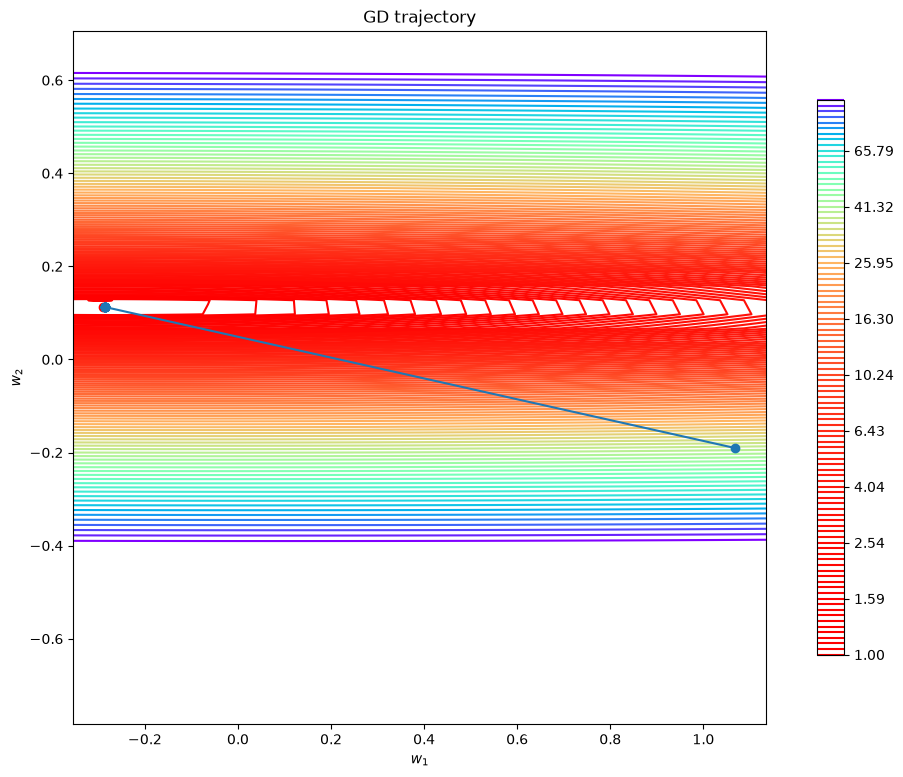

In [5]:
epochs = 10 # количество эпох обучения
np.random.seed(51)

n_dim = 2 # степень полинома
w_true = np.random.normal(0, 1, size=(n_dim, 1)) # настоящие параметры модели

# генерируем выборку
num_samples = 500  # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 100
x = np.concatenate([np.random.normal(0, 1, (num_samples, n_dim-1)),
                    np.random.normal(0, 20, (num_samples, 1))],axis=1)

y = x @ w_true + np.random.normal(0, sigma, (num_samples, 1))

w = np.random.normal(0, 1, size=(n_dim, 1))
w_list = [w.copy()]

for i in range(0,epochs):
    # Вычислите градиент
    grad = 2 / num_samples * x.T @ (x @ w - y)
    H = 2 / num_samples * x.T @ x
    # Измените параметры модели
    w = w - np.linalg.inv(H) @ grad 
    # Сохраняем веса в список
    w_list.append(w.copy())

w_exact = (np.linalg.inv(x.T @ x) @ x.T @ y)
print(f"Численное решение: {w.ravel()}")
print(f"Аналитическое решение: {w_exact.ravel()}")
print(f"Истинное значение: {w_true.ravel()}")
draw_descent(x, y, w_true, np.array(w_list))

Проблема кривизны решилась и сходимость к минимуму и правда достигается всего за один шаг!

## Задание:

Реализуйте класс, в котором будет возможность обучить линейную регрессию. Необходима возможность выбрать регуляризацию: без, $L_1$, $L_2$. Необходима возможность включения метода ньютона для обучения.

Если пространство весов двумерное, необходима возможность визуализации обучения: отрисовка линий уровня функции потери и линий уровня регуляризации, отрисовка пути изменения весов.

Подсказка:

|  Регуляризация  | Функция ошибки | Градиент | Гессиан |
|-----------------|----------------|----------|---------|
| Нет             | $\frac{1}{n}(Xw-y)^T(Xw-y)$             | $\frac{2}{n}X^T(Xw-y)$    | $\frac{2}{n}X^TX$ |
| $L_2$              | $+\alpha\sum_{i=1}^{d} w_i^2$           | $+2\alpha w$              | $+2\alpha E$      |
| $L_1$              | $+\alpha\sum_{i=1}^{d}\mid w_i \mid$    | $+\alpha sign(w)$         | Не существует     |


-------

$$
sign(w) = sign
\left(
    \begin{pmatrix}
    w_1\\
    \vdots\\
    w_d
    \end{pmatrix}
\right)
=
\begin{pmatrix}
    sign(w_1)\\
    \vdots\\
    sign(w_d)
    \end{pmatrix}
;\; sign(w_i)=\begin{cases}1,&  w_i>0\\-1,&  w_i<0\end{cases}$$

Стоит заметить, что при $L_1$ регуляризации градиент не существует, если одна из координат $w_i$ равна 0. Но нас этот момент волновать не будет. Равенство какого-то веса 0 можно пренебречь и считать градиент нулевым. 

А вот применять метод Ньютона для регрессии с $L_1$ регуляризацией нельзя из-за того, что функция потери становится не гладкой.

In [6]:
from typing import Literal, Optional, Union

class Regressor:
    """Линейная регрессия, обучаемая градиентным спуском / методом Ньютона.

    regularization : "None" | "L1" | "L2", alpha — коэффициент регуляризации.
    use_newton     : шаг Ньютона w <- w - newton_lr * H^{-1} grad (для L1 не применим).
    batch_size     : None — полный градиентный спуск (1 шаг за эпоху),
                     число — стохастический (мини-батчевый) спуск, за эпоху проход по всей перемешанной выборке.
    lr_decay       : False — без уменьшения темпа; True или "exp" — lr * decay_rate^t;
                     "step" — lr * decay_rate^(t // decay_step); "inv" — lr / (1 + decay_rate * t),
                     где t — номер шага обновления весов.
    """

    def __init__(self, lr=0.001, lr_decay: Union[bool, str] = False, epochs=100, use_newton=False,
                 regularization: Literal["None", "L1", "L2"] = "None", alpha=0.1,
                 batch_size: Optional[int] = None, decay_rate=0.95, decay_step=10, newton_lr=1.0):
        self.lr = lr
        self.lr_decay = lr_decay
        self.epochs = epochs
        self.use_newton = use_newton
        self.regularization = regularization
        self.alpha = alpha
        self.batch_size = batch_size
        self.decay_rate = decay_rate
        self.decay_step = decay_step
        self.newton_lr = newton_lr
        self.w_list = []
        self.w = None
        if self.regularization == "L1" and self.use_newton:
            raise Exception("Метод ньютона не применим к L1 регуляризации.")

    def loss(self, x: np.ndarray, y: np.ndarray, w: np.ndarray):
        """Возвращает (MSE, регуляризация) отдельно — удобно для отрисовки.
        w может быть формы (d, 1) или (d, N) — тогда считается сразу для N наборов весов."""
        mse = np.mean(np.square(x @ w - y), axis=0)
        if self.regularization == "None":
            reg = np.zeros_like(mse)
        elif self.regularization == "L2":
            reg = self.alpha * np.sum(np.square(w), axis=0)
        elif self.regularization == "L1":
            reg = self.alpha * np.sum(np.abs(w), axis=0)
        return mse, reg

    def total_loss(self, x, y, w):
        mse, reg = self.loss(x, y, w)
        return float((mse + reg).sum())

    def grad(self, x: np.ndarray, y: np.ndarray, w: np.ndarray):
        g = 2 / x.shape[0] * x.T @ (x @ w - y)
        if self.regularization == "L2":
            g = g + 2 * self.alpha * w
        elif self.regularization == "L1":
            g = g + self.alpha * np.sign(w)   # субградиент, в нуле берём 0
        return g

    def hessian(self, x: np.ndarray, y: np.ndarray, w: np.ndarray):
        H = 2 / x.shape[0] * x.T @ x
        if self.regularization == "L2":
            H = H + 2 * self.alpha * np.eye(w.shape[0])
        elif self.regularization == "L1":
            raise Exception("Для L1 регуляризации гессиан не существует.")
        return H

    def init_w(self, n_dim):
        """ Функция начальной инициализации весов."""
        return np.random.normal(0, 1, (n_dim, 1))

    def step_size(self, base, t):
        """Темп обучения на шаге t с учётом выбранной схемы уменьшения."""
        if not self.lr_decay:
            return base
        kind = "exp" if self.lr_decay is True else self.lr_decay
        if kind == "exp":
            return base * self.decay_rate ** t
        if kind == "step":
            return base * self.decay_rate ** (t // self.decay_step)
        if kind == "inv":
            return base / (1 + self.decay_rate * t)
        raise ValueError(f"Неизвестная схема уменьшения темпа: {kind}")

    def batches(self, n):
        if self.batch_size is None or self.batch_size >= n:
            yield np.arange(n)
            return
        idx = np.random.permutation(n)
        for start in range(0, n, self.batch_size):
            yield idx[start:start + self.batch_size]

    def fit(self, x, y):
        w = self.init_w(x.shape[1])
        w_list = [w.copy()]
        self.loss_history = [self.total_loss(x, y, w)]   # ошибка на всей выборке после каждого шага
        self.epoch_loss = [self.loss_history[0]]          # ... и после каждой эпохи
        t = 0
        for epoch in range(self.epochs):
            for idx in self.batches(x.shape[0]):
                xb, yb = x[idx], y[idx]
                g = self.grad(xb, yb, w)
                if self.use_newton:
                    H = self.hessian(xb, yb, w)
                    w = w - self.step_size(self.newton_lr, t) * np.linalg.solve(H, g)
                else:
                    w = w - self.step_size(self.lr, t) * g
                t += 1
                w_list.append(w.copy())
                self.loss_history.append(self.total_loss(x, y, w))
            self.epoch_loss.append(self.loss_history[-1])
        self.w_list = np.array(w_list)
        self.w = w
        return self

    def predict(self, x):
        return x @ self.w

    def show_training(self, w_true, x, y, ax=None, title=None, show_reg=True):
        """Линии уровня MSE (цветные), линии уровня регуляризации (серые пунктирные) и путь весов."""
        if self.w.shape[0] != 2:
            raise Exception("Веса должны быть размерности 2.")
        own_fig = ax is None
        if own_fig:
            fig, ax = plt.subplots(figsize=(10, 8))
        pts = np.vstack([self.w_list[:, :, 0], np.ravel(w_true)[None, :]])
        center = (pts.min(axis=0) + pts.max(axis=0)) / 2
        width = max(np.ptp(pts[:, 0]), np.ptp(pts[:, 1]), 0.5) / 2 * 1.2
        A, B = np.meshgrid(np.linspace(center[0] - width, center[0] + width, 300),
                           np.linspace(center[1] - width, center[1] + width, 300))
        W = np.vstack([A.ravel(), B.ravel()])
        mse, reg = self.loss(x, y, W)
        mse, reg = mse.reshape(A.shape), reg.reshape(A.shape)
        lv = mse.min() + (np.percentile(mse, 97) - mse.min()) * np.linspace(0, 1, 30) ** 2
        cs = ax.contour(A, B, mse, levels=lv[1:], cmap=plt.cm.rainbow_r, linewidths=0.8)
        if show_reg and self.regularization != "None":
            ax.contour(A, B, reg, levels=np.linspace(reg.min(), np.percentile(reg, 90), 10)[1:],
                       colors="gray", linestyles="--", linewidths=0.8)
        total = mse + reg
        k = np.unravel_index(total.argmin(), total.shape)
        ax.scatter(np.ravel(w_true)[0], np.ravel(w_true)[1], c="r", s=60, zorder=5, label="Истинные веса")
        ax.scatter(A[k], B[k], marker="X", c="green", s=90, zorder=6, label="Минимум MSE + рег.")
        ax.plot(self.w_list[:, 0, 0], self.w_list[:, 1, 0], "k.-", lw=0.8, ms=4, label="Траектория")
        ax.set_xlabel("$w_1$"); ax.set_ylabel("$w_2$"); ax.set_aspect("equal")
        ax.set_title(title or "Траектория обучения")
        ax.legend(fontsize=8, loc="best")
        if own_fig:
            plt.colorbar(cs, ax=ax, shrink=0.8)
            plt.show()
            return None
        return ax

Пример результатов работы класса:

In [7]:
# np.random.seed(51)

n_dim = 2 # степень полинома
w_true = np.random.normal(0, 1, size=(n_dim, 1)) # настоящие параметры модели
w_true = np.array([[0.4],[-0.1]])

# генерируем выборку
num_samples = 500  # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 100
x = np.concatenate([np.random.normal(0, 1, (num_samples, n_dim-1)),
                    np.random.normal(0, 1, (num_samples, 1))],axis=1)

y = x @ w_true + np.random.normal(0, sigma, (num_samples, 1))

Пример с $L_1$ регуляризацией:

Обученные веса: [ 0.36517822 -0.020934  ]
Настоящие веса: [ 0.4 -0.1]


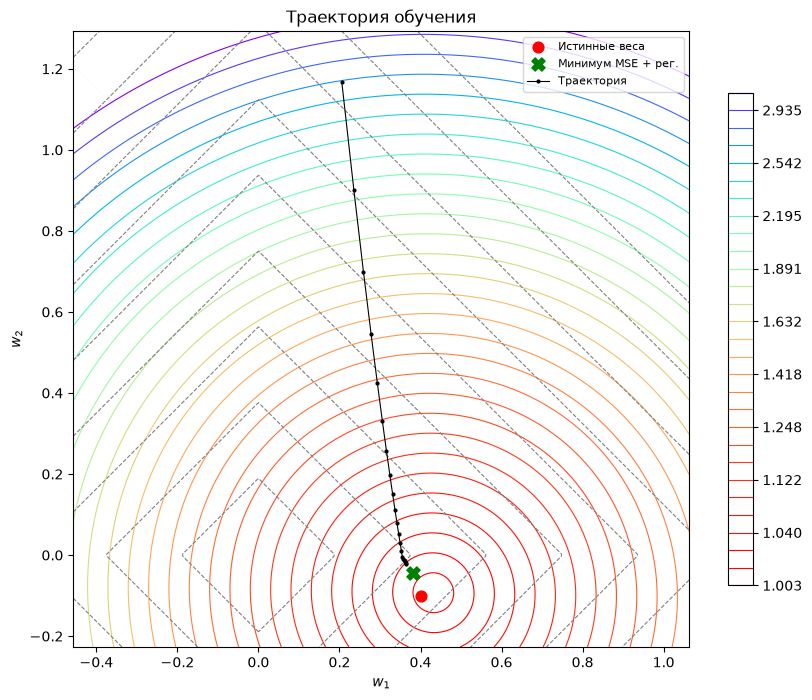

In [8]:
np.random.seed(53)
r = Regressor(lr=0.1, lr_decay=True, epochs=20, use_newton=False, regularization="L1", alpha=0.1)
r.fit(x, y)

print(f"Обученные веса: {r.w.ravel()}")
print(f"Настоящие веса: {w_true.ravel()}")
r.show_training(w_true, x, y)

$L_2$ регуляризация 

Обученные веса: [ 0.39159222 -0.0839359 ]
Настоящие веса: [ 0.4 -0.1]


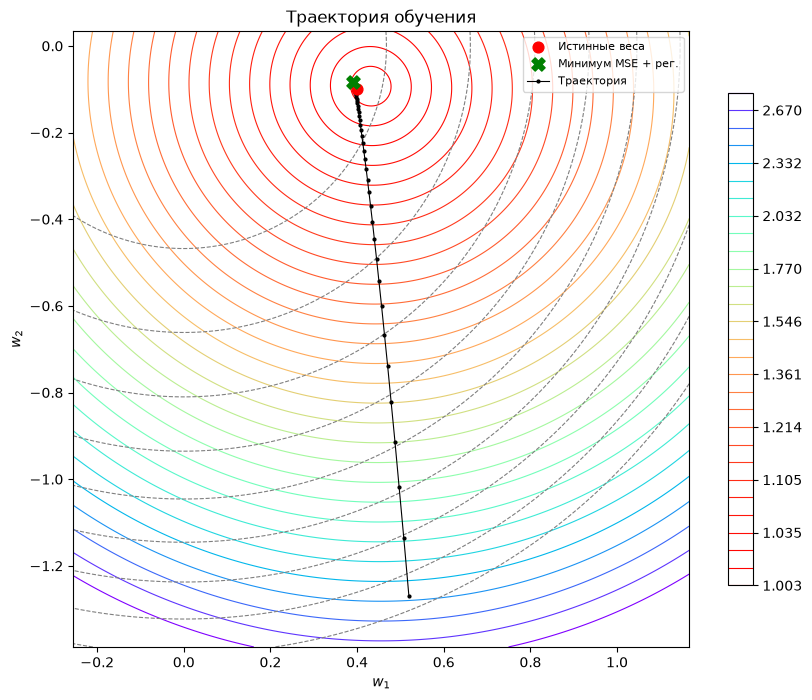

In [9]:
np.random.seed(52)
r = Regressor(lr=0.05, lr_decay=False, epochs=200, use_newton=False, regularization="L2", alpha=0.1)
r.fit(x, y)

print(f"Обученные веса: {r.w.ravel()}")
print(f"Настоящие веса: {w_true.ravel()}")
r.show_training(w_true, x, y)

$L_2$ регуляризация с методом Ньютона и большим перекосом в масштабе данных.

Обученные веса: [ 0.38749426 -0.19877261]
Настоящие веса: [ 0.4 -0.2]


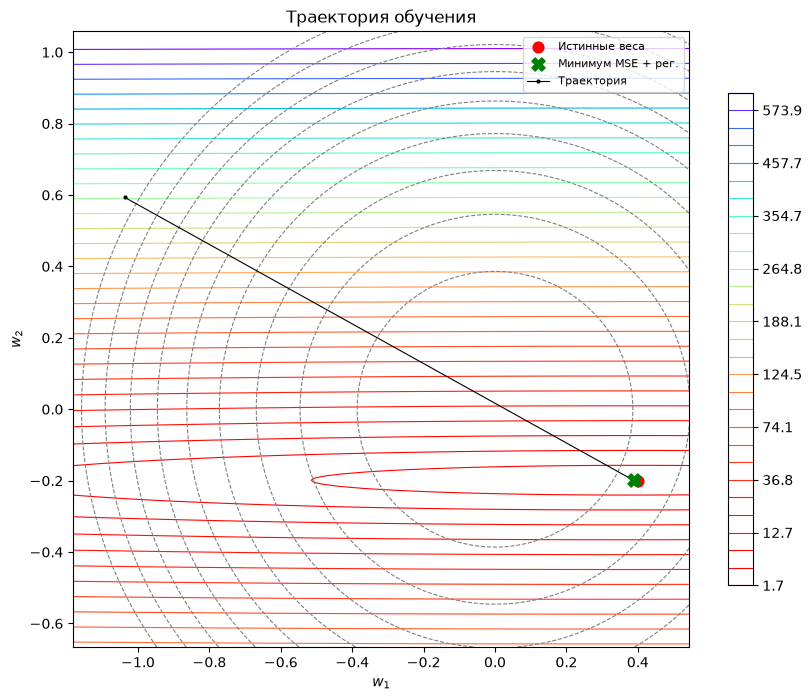

In [10]:
n_dim = 2 # степень полинома
w_true = np.random.normal(0, 1, size=(n_dim, 1)) # настоящие параметры модели
w_true = np.array([[0.4], [-0.2]])

# генерируем выборку
num_samples = 500  # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 100
x = np.concatenate([np.random.normal(0, 1, (num_samples, n_dim-1)),
                    np.random.normal(0, 20, (num_samples, 1))],axis=1)

y = x @ w_true + np.random.normal(0, sigma, (num_samples, 1))

np.random.seed(56)
r = Regressor(epochs=20, use_newton=True, regularization="L2", alpha=0.001)
r.fit(x, y)

print(f"Обученные веса: {r.w.ravel()}")
print(f"Настоящие веса: {w_true.ravel()}")
r.show_training(w_true, x, y)

На этом примере можно снова отметить, что метод Ньютона для Ridge-регрессии снова сошёлся за один шаг. 

## Стохастический градиентный спуск

Стоит отметить, что метод Ньютона имеет очень ограниченное применение. 
- Как уже отмечалось выше, он не применим если функция не гладкая
- Метод ньютона ведёт в экстремум, а не в минимум.
- Требует обращения квадратной матрицы размера $(d,d)$.

Касаемо применения метода Ньютона в <b>нейронных сетях</b> больше всего проблем доставляет именно последний пункт. Как правило, вектор весов в нейронных сетях огромен. К примеру, в GPT-4 количество весов оценивается числом $10^{14}$, а в простых вариантах свёрточных нейронных сетей, которые мы пообучаем уже на другом курсе, обычно содержится несколько миллионов весов. Поэтому вычисление Гессиана становится непосильной задачей. Стоит отметить, что существуют квазиньютоновские методы, которые строят приближения Гессиана при помощи значений самой функции ошибки и её градиента. Но применять их тоже не удаётся. Для хорошего приближения необходимо хотя-бы знать значение градиента функции, но даже этого не удаётся. А связано это с темой нашего следующего разговора.

В реальных задачах машинного обучения наборы данных, действительно позволяющие решать задачи, огромны. Классический набор данных для классификации изображений, [ImageNet](https://image-net.org/download.php) содержит более миллиона изображений. А для получения градиента функции ошибки необходимо посчитать градиент для каждой точки данных и усреднить их. Так, даже вычисление градиента всей функции ошибки оказывается трудоёмким занятием как касательно затрачиваемого времени, так и касательно необходимых затрат памяти. К примеру, тот же набор данных ImageNet Весит примерно 160ГБ, а для вычисления градиента нам эти данные надо записать в память и произвести некоторые операции.

Решением проблемы становится применение <b>стохастического градиентного спуска</b> (stochastic gradient descent, SGD), который за один шаг оптимизации вычисляет градиент не по всей выборке, а по некоторой подвыборке. 

Математически это можно обосновать следующим образом: минимизация функции ошибки это минимизация матожидания ошибки по выборке (Если считать, что элементы данных выбираются равномерно):

$$L(w)=\frac{1}{n}\sum_{i=1}^{n}f_i(w)=\mathbb{E}_{i\sim Unif(1,...,N)}f_i(w).$$

В свою очередь, метод стохастического градиентного спуска строит оценки матожидания функции ошибки на основании среднего по подвыборке:

$$\hat{L}(w)=\frac{1}{m}\sum_{i=1}^{m}f_{j_i}(w)$$

где $j_1,\dots,j_m$ - подвыборка, сгенерированная равномерно.

Стоит отметить, что получаемые оценки имеют хорошие свойства, они состоятельные и несмещённые.

Наконец, на основании оценки функции ошибки можно построить оценку градиента функции ошибки:

$$\nabla_w\hat{L}(w)=\frac{1}{m}\sum_{i=1}^{m}\nabla_wf_{j_i}(w).$$

Тем не менее стоит отметить, что дисперсия такой оценки при небольшом размере подвыборки будет велика. Тут уже видна проблема применеия квазиньютоновских методов. Из-за большой дисперсии оценки градиента оценка Гессиана оказывается неприменимой.

По той же причине большой дисперсии стохастический градиентный спуск никогда не будет двигаться в точности в правильном направлении. Также даже в точке оптимума оценка градиента не будет равна 0 и алгоритм продолжит блуждать в окрестности минимума. А размер окрестности будет зависеть от параметра темпа обучения.

Из-за проблемы блуждания в окрестности минимума имеет смысл по ходу алгоритма уменьшать темп обучения. Точного ответа как именно необходимо уменьшать темп обучения нет. Можно использовать стандартные зависимости: 
 - линейная:
 $$\alpha=\alpha_0\left(1-\frac{t}{T}\right),$$
 - экспоненциальная:
 $$\alpha=\alpha_0e^{-\frac{t}{T}}.$$

Реализуйте стохастический градиентный спуск: равномерно сгенерируйте подвыборку и посчитайте по ней градиент.

Опробуйте разные параметры размера подвыборки, темпа обучения и способа уменьшения темпа обучения.

Обновлённый алгоритм градиентного спуска будет выглядеть так:

0. Начальная инициализация параметров: $w^{(0)}$.
1. Генерация подвыборки $X'$ и $y'$.
2. Вычисляем гардиент: $\nabla L_w(X',y',w^{(t)})$.
3. Меняем параметры модели: $w^{(t+1)}=w^{(t)}-\alpha\nabla L_w(X',y',w^{(t)})$.
4. Обновляем темп обучения $\alpha$.
5. Переходим к шагу 1.

Численное решение: [ 1.07733841 -0.49429827]
Аналитическое решение: [ 1.06931139 -0.48749297]
Истинное значение: [ 1.10268062 -0.51217773]


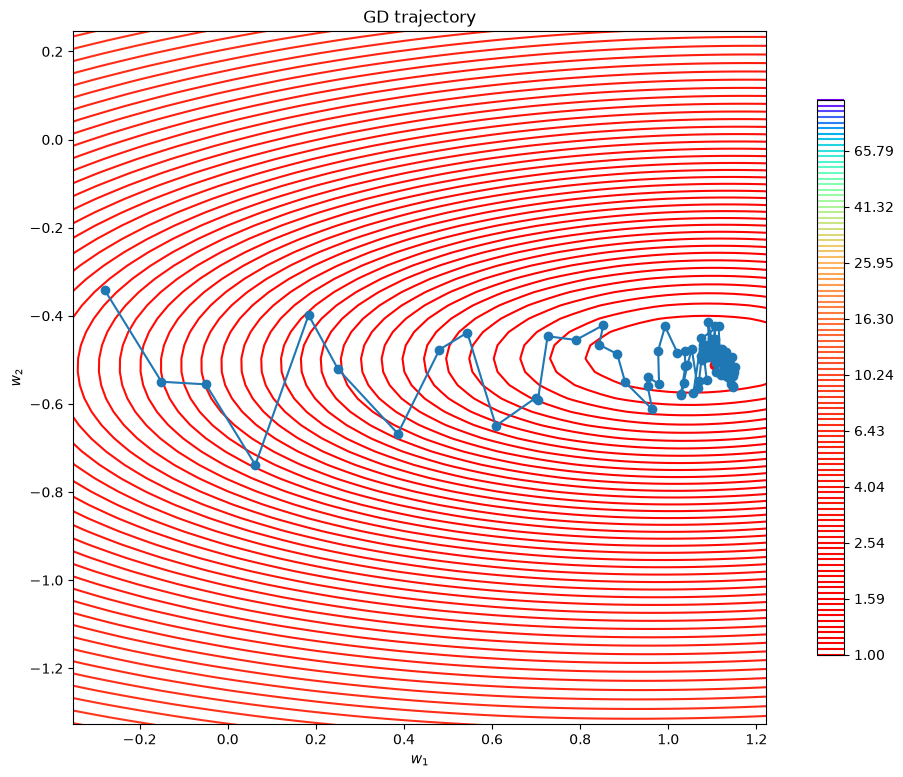

In [11]:
learning_rate = 0.05 # темп обучения
epochs = 100 # количество эпох обучения
batch_size = 10 # размер подвыборки

n_dim = 2 # степень полинома
w_true = np.random.normal(0, 1, (n_dim, 1)) # настоящие параметры модели
# генерируем выборку
num_samples = 500  # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 100
x = np.hstack([np.ones((num_samples, 1)),
        np.random.uniform(-5, 5, (num_samples, n_dim - 1))])
    
y = x @ w_true + np.random.normal(0, sigma, (num_samples, 1))

w = np.random.normal(0, 1, (n_dim, 1))
w_list = [w.copy()]

for i in range(0,epochs):
    # Вычисляем градиент
    indices = np.random.randint(0,x.shape[0], batch_size)
    grad = 2 / batch_size * x[indices].T @ (x[indices] @ w - y[indices])
    # Изменяем параметры модели
    w = w - learning_rate * grad
    # Сохраняем веса в список
    w_list.append(w.copy())
    learning_rate = learning_rate * 0.98

w_exact = (np.linalg.inv(x.T @ x) @ x.T @ y)
print(f"Численное решение: {w.ravel()}")
print(f"Аналитическое решение: {w_exact.ravel()}")
print(f"Истинное значение: {w_true.ravel()}")
draw_descent(x, y, w_true, np.array(w_list))

<b>Замечание</b>

Важно отметить, что ранее <i>количеством эпох</i> мы называли количество шагов обновления градиента, и это и правда было так. Обычно же под количеством эпох понимают количество проходов вычисления градиента по всей выборке. 

Для этого надо создать массив индексов от $0$ до $n$ и перемешать. Далее необходимо проитерироваться по этому массиву и вычислить градиенты по подвыборкам.

Заметьте насколько стохастический градиентный спуск быстрее обычного: 
- Сократились затраты по памяти, а при обучении нейронных сетей это одна из больших проблем;
- Сократились затраты по времени на вычисление градиента;
- После прохода по всей выборке будет сделан не один градиентный шаг, а целых $\frac{n}{batch\_size}$.

Численное решение: [-0.97655838  0.004296  ]
Аналитическое решение: [-1.02138551  0.00125683]
Истинное значение: [-1.02032024  0.00307999]


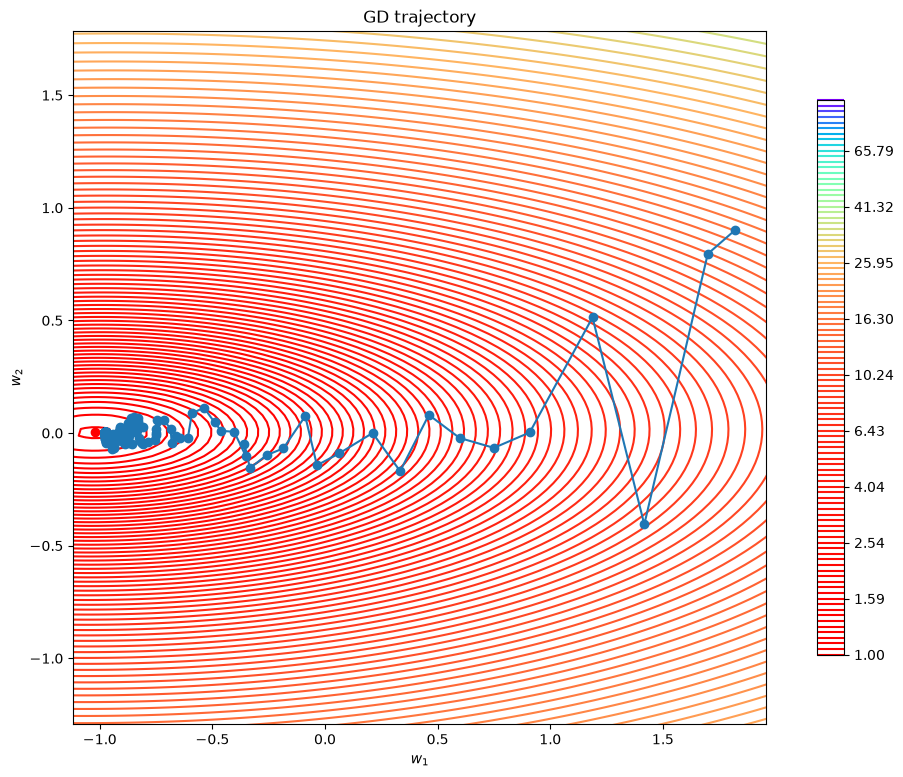

In [12]:
learning_rate = 0.05 # темп обучения
epochs = 10 # количество эпох обучения
batch_size = 10 # размер подвыборки

n_dim = 2 # степень полинома
w_true = np.random.normal(0, 1, (n_dim, 1)) # настоящие параметры модели
# генерируем выборку
num_samples = 5000  # Размер выборки
sigma = 1          # Дисперсия шума
x_min, x_max = 0, 100
x = np.hstack([np.ones((num_samples, 1)),
        np.random.uniform(-5, 5, (num_samples, n_dim - 1))])
    
y = x @ w_true + np.random.normal(0, sigma, (num_samples, 1))

w = np.random.normal(0, 1, (n_dim, 1))
w_list = [w.copy()]
# Создаём массив индексов
indexes = np.arange(x.shape[0])

for i in range(0,epochs):
    # Перемешиваем индексы
    np.random.shuffle(indexes)
    for i in range(0, x.shape[0] // batch_size):
        indices = indexes[i * batch_size: (i+1) * batch_size]
        # Вычисляем градиент
        grad = 2 / batch_size * x[indices].T @ (x[indices] @ w - y[indices])
        # Изменяем параметры модели
        w = w - learning_rate * grad
        # Сохраняем веса в список
        w_list.append(w.copy())
        learning_rate = learning_rate * 0.98

w_exact = (np.linalg.inv(x.T @ x) @ x.T @ y)
print(f"Численное решение: {w.ravel()}")
print(f"Аналитическое решение: {w_exact.ravel()}")
print(f"Истинное значение: {w_true.ravel()}")
draw_descent(x, y, w_true, np.array(w_list))

<b>Задание</b>: доработайте класс `Regressor`, добавьте реализацию стохастического градиентного спуска, добавьте механизм уменьшения темпа обучения. Посмотрите как работает метод Ньютона в комбинации с стохастическим градиентным спуском?

# Домашнее задание

- Расписать частную производную для Гессиана. Ранее в тексте упоминалось, что задание расписать одну формулу идёт на дом.
- Написать класс для обучения линейной регрессии с разными регуляризациями и методом Ньютона. Необходимо доработать предоставленный класс Regressor.
- Дополнить класс реализацией стохастического градиентного спуска.

---
# Решение домашнего задания

## 1. Частные производные и гессиан

**Упражнение из текста.** Квадратичное приближение функции потерь:

$$\tilde L(w) = L(w^{(t)})+\nabla L(w^{(t)})^T(w-w^{(t)})+\frac{1}{2}(w-w^{(t)})^TH_t(w-w^{(t)}).$$

Обозначим $\delta = w - w^{(t)}$, $g=\nabla L(w^{(t)})$. Распишем по координатам:

$$\tilde L(w) = L(w^{(t)}) + \sum_{k} g_k\delta_k + \frac{1}{2}\sum_{k}\sum_{l}H_{kl}\,\delta_k\delta_l.$$

Частная производная по $w_j$ (от $w_j$ зависит только $\delta_j$, $\partial\delta_k/\partial w_j = [k=j]$):

$$\frac{\partial \tilde L}{\partial w_j} = g_j + \frac{1}{2}\Big(\sum_{l}H_{jl}\delta_l + \sum_{k}H_{kj}\delta_k\Big) = g_j + \sum_{l}H_{jl}\delta_l,$$

где на последнем шаге использована симметричность гессиана $H_{kj}=H_{jk}$ (вторые производные непрерывны, теорема Шварца). В векторной форме: $\nabla \tilde L(w)=\nabla L(w^{(t)}) + H_t(w-w^{(t)})$, что и требовалось.

**Гессиан для MSE.** $L(w)=\frac{1}{n}\sum_{i=1}^n\big(\sum_k x_{ik}w_k - y_i\big)^2$.

$$\frac{\partial L}{\partial w_j} = \frac{2}{n}\sum_{i=1}^n\Big(\sum_k x_{ik}w_k - y_i\Big)x_{ij}\quad\Rightarrow\quad \nabla L = \frac{2}{n}X^T(Xw-y),$$

$$\frac{\partial^2 L}{\partial w_j\,\partial w_l} = \frac{2}{n}\sum_{i=1}^n x_{ij}\,x_{il}\quad\Rightarrow\quad H = \frac{2}{n}X^TX.$$

Гессиан не зависит от $w$ — функция квадратичная, и её разложение Тейлора второго порядка точное. Поэтому метод Ньютона из любой точки попадает в минимум за один шаг: $w^{(1)} = w^{(0)} - \frac{n}{2}(X^TX)^{-1}\cdot\frac{2}{n}X^T(Xw^{(0)}-y) = (X^TX)^{-1}X^Ty$.

**L2:** $\frac{\partial}{\partial w_j}\alpha\sum_k w_k^2 = 2\alpha w_j$, $\frac{\partial^2}{\partial w_j\partial w_l} = 2\alpha[j=l]$, т.е. добавка $2\alpha E$.
Матрица $\frac{2}{n}X^TX + 2\alpha E$ положительно определена при любом $\alpha>0$ — поэтому Ridge всегда имеет единственное решение.

**L1:** $\frac{\partial}{\partial w_j}\alpha\sum_k |w_k| = \alpha\,\mathrm{sign}(w_j)$ при $w_j\ne0$; вторая производная равна 0 везде, кроме $w_j=0$, где не существует даже первая. Поэтому гессиан L1-члена «бесполезен», а метод Ньютона неприменим.

Проверю аналитические формулы численно (конечными разностями):

In [13]:
import json
from sklearn.linear_model import Ridge, Lasso
RESULTS = {}

np.random.seed(1)
Xc = np.random.normal(0, 1, (50, 3)); yc = np.random.normal(0, 1, (50, 1)); wc = np.random.normal(0, 1, (3, 1))
eps = 1e-5
for reg in ["None", "L2"]:
    m = Regressor(regularization=reg, alpha=0.3)
    f = lambda w: m.total_loss(Xc, yc, w)
    g_num = np.array([[(f(wc + eps * e[:, None]) - f(wc - eps * e[:, None])) / (2 * eps)] for e in np.eye(3)]).reshape(3, 1)
    gfun = lambda w: m.grad(Xc, yc, w)
    H_num = np.hstack([(gfun(wc + eps * e[:, None]) - gfun(wc - eps * e[:, None])) / (2 * eps) for e in np.eye(3)])
    print(f"{reg}: |grad - grad_num| = {np.abs(m.grad(Xc, yc, wc) - g_num).max():.1e}, "
          f"|H - H_num| = {np.abs(m.hessian(Xc, yc, wc) - H_num).max():.1e}")

None: |grad - grad_num| = 3.5e-11, |H - H_num| = 2.6e-11
L2: |grad - grad_num| = 2.6e-11, |H - H_num| = 3.1e-11


## 2. Класс `Regressor`

Класс реализован выше (ячейка с определением класса заменена полной реализацией), примеры из занятия с ним работают. Что сделано:
- `loss` возвращает MSE и регуляризационное слагаемое отдельно и работает сразу для матрицы весов `(d, N)` — так линии уровня считаются без циклов;
- `grad` и `hessian` — по формулам из таблицы (для L1 используется субградиент `sign(w)`, гессиана нет);
- `fit` поддерживает обычный градиентный спуск, метод Ньютона, стохастический спуск с мини-батчами и три схемы уменьшения темпа обучения;
- `show_training` рисует линии уровня MSE, линии уровня регуляризатора (серым пунктиром), истинные веса, минимум полной функции потерь и траекторию весов.

Важная деталь: в исходной версии `lr_decay` уменьшал `self.lr` прямо в объекте, и повторный `fit` начинался уже с маленького темпа. Сейчас темп вычисляется по номеру шага, и объект можно переобучать.

### Проверка корректности

Сравниваю с аналитическим решением и со `sklearn`. Масштаб регуляризации у нас и в `sklearn` разный:
- у нас $L=\frac{1}{n}\|Xw-y\|^2+\alpha\|w\|_2^2$, у `Ridge` — $\|Xw-y\|^2+\alpha'\|w\|_2^2$, значит $\alpha'=n\alpha$;
- у `Lasso` — $\frac{1}{2n}\|Xw-y\|^2+\alpha'\|w\|_1$, значит $\alpha'=\alpha/2$.

In [14]:
np.random.seed(5)
n = 500
X2 = np.random.normal(0, 1, (n, 2))
w_true2 = np.array([[0.4], [-0.1]])
y2 = X2 @ w_true2 + np.random.normal(0, 1, (n, 1))
alpha = 0.1

rows = []
w_ols = np.linalg.solve(X2.T @ X2, X2.T @ y2)
w_ridge = Ridge(alpha=n * alpha, fit_intercept=False).fit(X2, y2).coef_.reshape(-1, 1)
w_lasso = Lasso(alpha=alpha / 2, fit_intercept=False).fit(X2, y2.ravel()).coef_.reshape(-1, 1)
configs = [
    ("Без рег., GD",      dict(lr=0.1, epochs=300, regularization="None"), w_ols),
    ("Без рег., Ньютон",  dict(epochs=1, use_newton=True, regularization="None"), w_ols),
    ("L2, GD",            dict(lr=0.1, epochs=300, regularization="L2", alpha=alpha), w_ridge),
    ("L2, Ньютон",        dict(epochs=1, use_newton=True, regularization="L2", alpha=alpha), w_ridge),
    ("L1, GD + затухание", dict(lr=0.1, epochs=1000, regularization="L1", alpha=alpha, lr_decay="inv", decay_rate=0.01), w_lasso),
]
for name, kw, ref in configs:
    m = Regressor(**kw).fit(X2, y2)
    rows.append([name, np.round(m.w.ravel(), 4).tolist(), np.round(ref.ravel(), 4).tolist(), float(np.abs(m.w - ref).max())])
    print(f"{name:20s} наш: {m.w.ravel().round(4)}  эталон: {ref.ravel().round(4)}  max|разность| = {np.abs(m.w - ref).max():.1e}")
RESULTS["check"] = rows

Без рег., GD         наш: [ 0.4434 -0.0979]  эталон: [ 0.4434 -0.0979]  max|разность| = 8.3e-17
Без рег., Ньютон     наш: [ 0.4434 -0.0979]  эталон: [ 0.4434 -0.0979]  max|разность| = 5.0e-16
L2, GD               наш: [ 0.4028 -0.0879]  эталон: [ 0.4028 -0.0879]  max|разность| = 1.1e-16
L2, Ньютон           наш: [ 0.4028 -0.0879]  эталон: [ 0.4028 -0.0879]  max|разность| = 1.8e-15
L1, GD + затухание   наш: [ 0.3922 -0.045 ]  эталон: [ 0.3922 -0.045 ]  max|разность| = 1.8e-10


Все варианты совпадают с эталоном. Для L1 точное совпадение получается только с уменьшением темпа обучения: субградиент `sign(w)` не стремится к нулю около минимума, и при постоянном шаге веса «дрожат» вокруг решения с амплитудой порядка `lr·alpha`.

### Визуализация обучения

Беру выборку, в которой второй истинный вес мал, и сравниваю траектории при разных регуляризациях (для наглядности `alpha` побольше).

Без регуляризации, GD               -> w = [0.997 0.334]
L2 (alpha=0.8), GD                  -> w = [0.563 0.174]
L1 (alpha=0.8), GD с затуханием     -> w = [0.605 0.005]


L2 (alpha=0.8), метод Ньютона       -> w = [0.563 0.174]


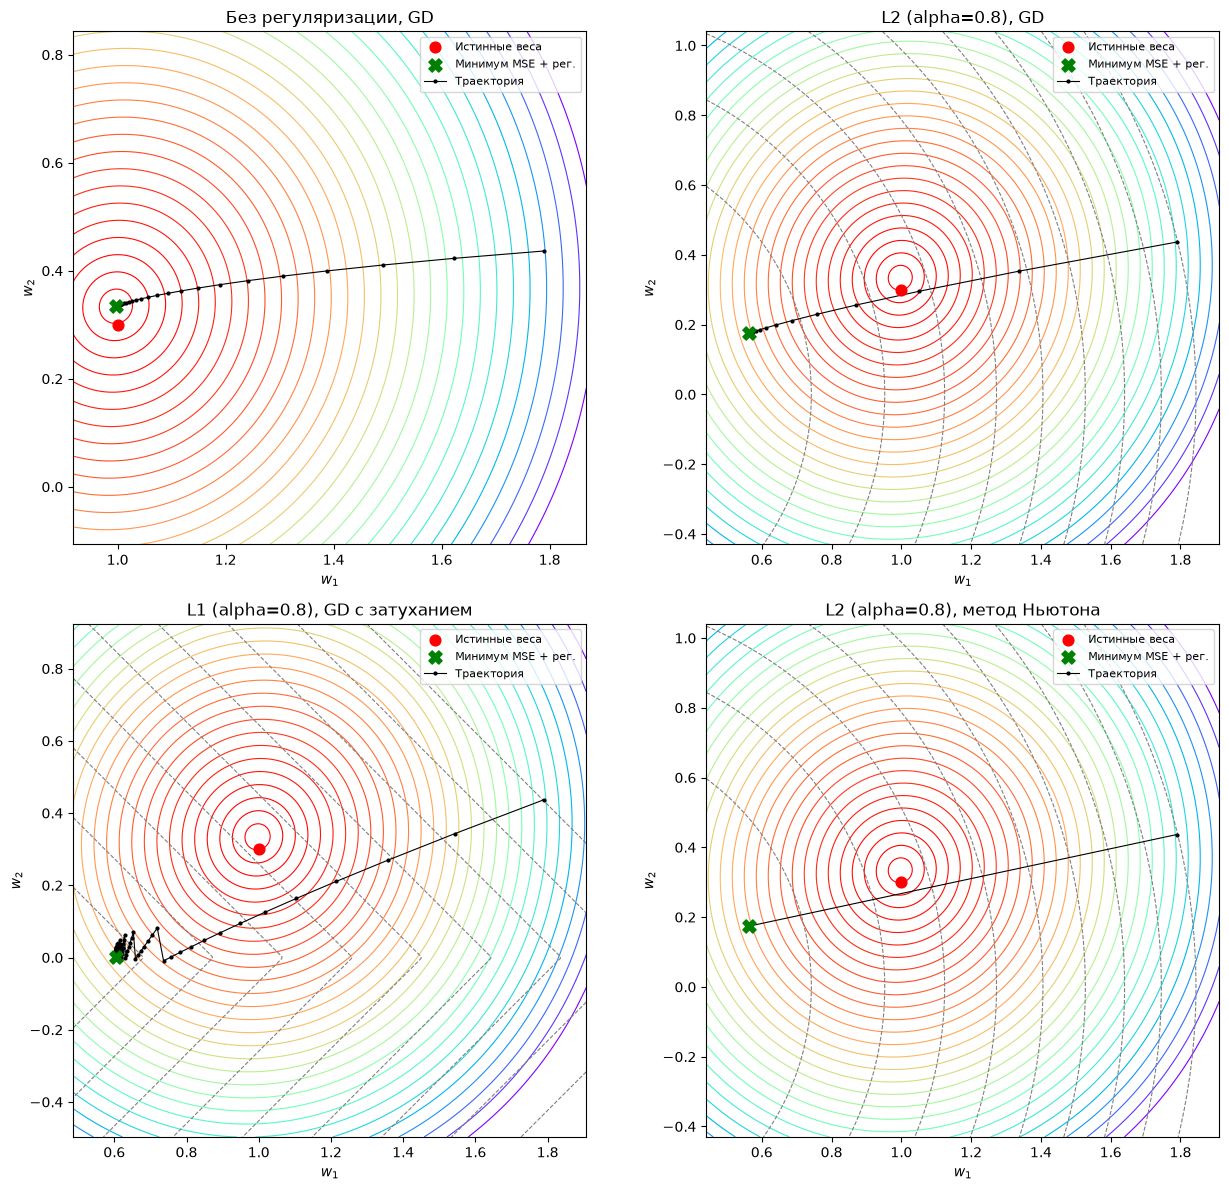

Эталон sklearn Lasso (alpha=0.8/2): [0.604 0.   ]


In [15]:
np.random.seed(11)
X3 = np.random.normal(0, 1, (500, 2))
w_true3 = np.array([[1.0], [0.3]])
y3 = X3 @ w_true3 + np.random.normal(0, 1, (500, 1))

fig, axes = plt.subplots(2, 2, figsize=(13, 12))
experiments = [
    (dict(lr=0.1, epochs=40, regularization="None"), "Без регуляризации, GD"),
    (dict(lr=0.1, epochs=40, regularization="L2", alpha=0.8), "L2 (alpha=0.8), GD"),
    (dict(lr=0.1, epochs=300, regularization="L1", alpha=0.8, lr_decay="inv", decay_rate=0.05), "L1 (alpha=0.8), GD с затуханием"),
    (dict(epochs=3, use_newton=True, regularization="L2", alpha=0.8), "L2 (alpha=0.8), метод Ньютона"),
]
traj = {}
for ax, (kw, title) in zip(axes.ravel(), experiments):
    np.random.seed(3)
    m = Regressor(**kw).fit(X3, y3)
    m.show_training(w_true3, X3, y3, ax=ax, title=title)
    traj[title] = m.w.ravel().round(3).tolist()
    print(f"{title:35s} -> w = {m.w.ravel().round(3)}")
fig.tight_layout()
fig.savefig("figures/trajectories.png", dpi=130, bbox_inches="tight")
plt.show()
RESULTS["trajectories"] = traj
print("Эталон sklearn Lasso (alpha=0.8/2):", Lasso(alpha=0.4, fit_intercept=False).fit(X3, y3.ravel()).coef_.round(3))

Что видно:
- без регуляризации траектория идёт в минимум MSE (рядом с истинными весами, отличие из-за шума);
- с L2 минимум сдвигается к нулю «пропорционально» — оба веса уменьшаются; минимум — точка касания эллипса MSE и окружности регуляризатора;
- с L1 минимум оказывается на оси $w_2=0$: маленький вес занулился (у нашего GD $w_2$ стремится к нулю и после 300 эпох уже ≈0.005, точное решение `sklearn.Lasso` — ровно 0), а $w_1$ просто уменьшился на постоянную величину $pproxlpha/2$. Это «угол ромба» L1 — именно поэтому Lasso отбирает признаки. Возле оси траектория «пилит» туда-обратно из-за разрыва субградиента;
- метод Ньютона приходит в минимум за один шаг, остальные шаги стоят на месте.

## 3. Стохастический градиентный спуск

Реализован в `fit` через параметр `batch_size`: на каждой эпохе индексы перемешиваются, выборка делится на мини-батчи, и градиент считается по батчу. Сравниваю на выборке из 5000 точек с ровно тем же числом эпох:
- полный GD,
- SGD с постоянным темпом,
- SGD с тремя схемами уменьшения темпа (экспоненциальная, ступенчатая, обратно пропорциональная),
- SGD с разными размерами батча.

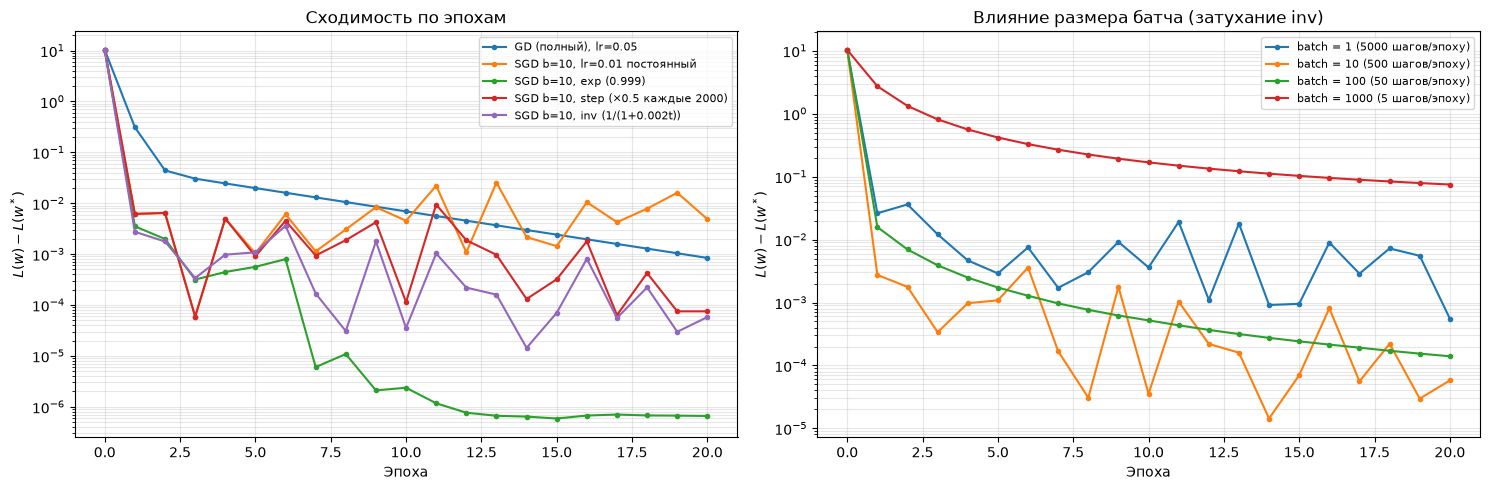

GD (полный), lr=0.05                   шагов:     20  ||w - w*|| = 2.90e-02  L - L* = 8.41e-04
SGD b=10, lr=0.01 постоянный           шагов:  10000  ||w - w*|| = 2.67e-02  L - L* = 4.86e-03
SGD b=10, exp (0.999)                  шагов:  10000  ||w - w*|| = 6.75e-04  L - L* = 6.58e-07
SGD b=10, step (×0.5 каждые 2000)      шагов:  10000  ||w - w*|| = 3.08e-03  L - L* = 7.50e-05
SGD b=10, inv (1/(1+0.002t))           шагов:  10000  ||w - w*|| = 2.75e-03  L - L* = 5.79e-05


In [16]:
np.random.seed(21)
n4 = 5000
X4 = np.hstack([np.ones((n4, 1)), np.random.uniform(-5, 5, (n4, 1))])
w_true4 = np.array([[1.5], [-0.7]])
y4 = X4 @ w_true4 + np.random.normal(0, 1, (n4, 1))
w_exact4 = np.linalg.solve(X4.T @ X4, X4.T @ y4)
L_opt = Regressor().total_loss(X4, y4, w_exact4)

runs = {
    "GD (полный), lr=0.05":               dict(lr=0.05, epochs=20),
    "SGD b=10, lr=0.01 постоянный":        dict(lr=0.01, epochs=20, batch_size=10),
    "SGD b=10, exp (0.999)":               dict(lr=0.01, epochs=20, batch_size=10, lr_decay="exp", decay_rate=0.999),
    "SGD b=10, step (×0.5 каждые 2000)":   dict(lr=0.01, epochs=20, batch_size=10, lr_decay="step", decay_rate=0.5, decay_step=2000),
    "SGD b=10, inv (1/(1+0.002t))":        dict(lr=0.01, epochs=20, batch_size=10, lr_decay="inv", decay_rate=0.002),
}
fitted = {}
for name, kw in runs.items():
    np.random.seed(0)
    fitted[name] = Regressor(**kw).fit(X4, y4)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for name, m in fitted.items():
    ax[0].plot(np.arange(len(m.epoch_loss)), np.array(m.epoch_loss) - L_opt + 1e-12, marker=".", label=name)
ax[0].set_yscale("log"); ax[0].set_xlabel("Эпоха"); ax[0].set_ylabel("$L(w) - L(w^*)$")
ax[0].set_title("Сходимость по эпохам"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, which="both")

for b in [1, 10, 100, 1000]:
    np.random.seed(0)
    m = Regressor(lr=0.01, epochs=20, batch_size=b, lr_decay="inv", decay_rate=0.002 * b / 10).fit(X4, y4)
    ax[1].plot(np.arange(len(m.epoch_loss)), np.array(m.epoch_loss) - L_opt + 1e-12, marker=".", label=f"batch = {b} ({n4 // b} шагов/эпоху)")
ax[1].set_yscale("log"); ax[1].set_xlabel("Эпоха"); ax[1].set_ylabel("$L(w) - L(w^*)$")
ax[1].set_title("Влияние размера батча (затухание inv)"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3, which="both")
fig.tight_layout(); fig.savefig("figures/sgd_convergence.png", dpi=150, bbox_inches="tight"); plt.show()

sgd_table = []
for name, m in fitted.items():
    sgd_table.append([name, len(m.loss_history) - 1, float(np.linalg.norm(m.w - w_exact4)), float(m.epoch_loss[-1] - L_opt)])
    print(f"{name:38s} шагов: {len(m.loss_history) - 1:6d}  ||w - w*|| = {np.linalg.norm(m.w - w_exact4):.2e}  L - L* = {m.epoch_loss[-1] - L_opt:.2e}")
RESULTS["sgd_table"] = sgd_table

Выводы по SGD:
- Уже после первой эпохи SGD (500 шагов по батчам из 10) находится гораздо ближе к минимуму, чем полный GD после одной эпохи (1 шаг): за одинаковое число просмотренных объектов SGD делает в `n / batch_size` раз больше шагов.
- С постоянным темпом SGD быстро выходит на «плато шума»: градиент по батчу — несмещённая, но шумная оценка, и веса блуждают вокруг минимума на расстоянии, пропорциональном `lr`. Чтобы сойтись точно, темп нужно уменьшать; все три схемы затухания это делают и опускают ошибку на порядки ниже.
- В этом эксперименте лучше всех сработало экспоненциальное затухание, но его коэффициент пришлось подобрать под общее число шагов (за 10000 шагов темп уменьшается в $0.999^{10000}pprox 5\cdot10^{-5}$ раз). Если затухание слишком быстрое, обучение «замерзает» раньше, чем дойдёт до минимума, поэтому на практике часто используют более «безопасные» ступенчатую схему или $1/t$.
- Размер батча — компромисс: маленький батч даёт много шагов за эпоху и быстрое начальное снижение, но шумный градиент; большой батч ближе к полному GD и делает мало шагов (при `batch=1000` всего 5 шагов за эпоху, и при том же темпе он отстаёт).

Пример траектории SGD:

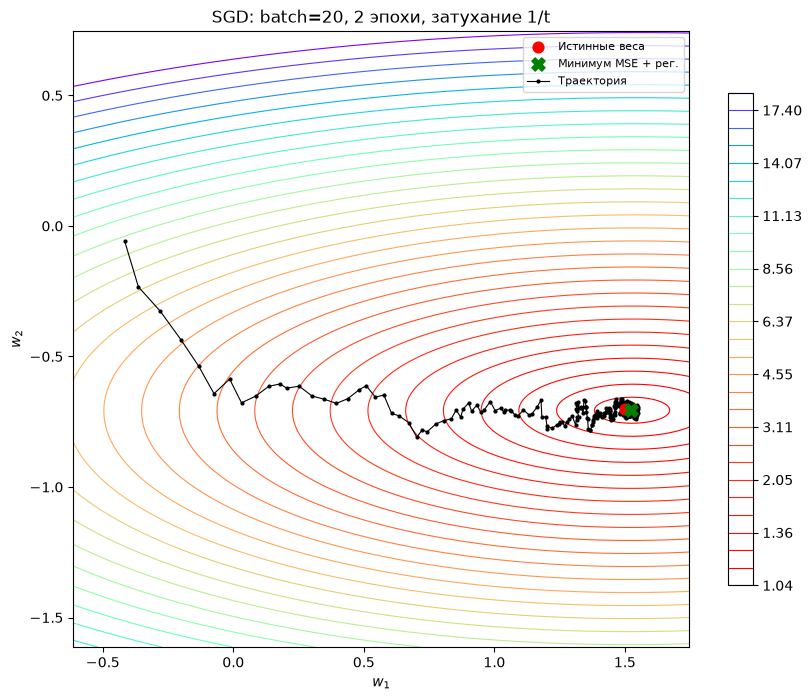

In [17]:
np.random.seed(2)
m = Regressor(lr=0.02, epochs=2, batch_size=20, lr_decay="inv", decay_rate=0.01).fit(X4, y4)
m.show_training(w_true4, X4, y4, title="SGD: batch=20, 2 эпохи, затухание 1/t")

## 4. Метод Ньютона + стохастический градиентный спуск

На мини-батче гессиан тоже можно оценить по батчу: $H_b=\frac{2}{b}X_b^TX_b(+2\alpha E)$. Тогда шаг Ньютона на батче — это переход в точку минимума *ошибки на этом батче*, т.е. в решение МНК по 10–20 точкам. Ожидаю, что без демпфирования веса будут «прыгать» между решениями разных батчей и не сойдутся. Сравню на плохо обусловленной выборке (масштабы признаков отличаются в 20 раз), где обычный GD страдает.

Собственные числа гессиана: [  2.01 823.73], число обусловленности = 410
GD устойчив при lr < 2/lambda_max = 0.0024; беру lr = 1/lambda_max = 0.0012


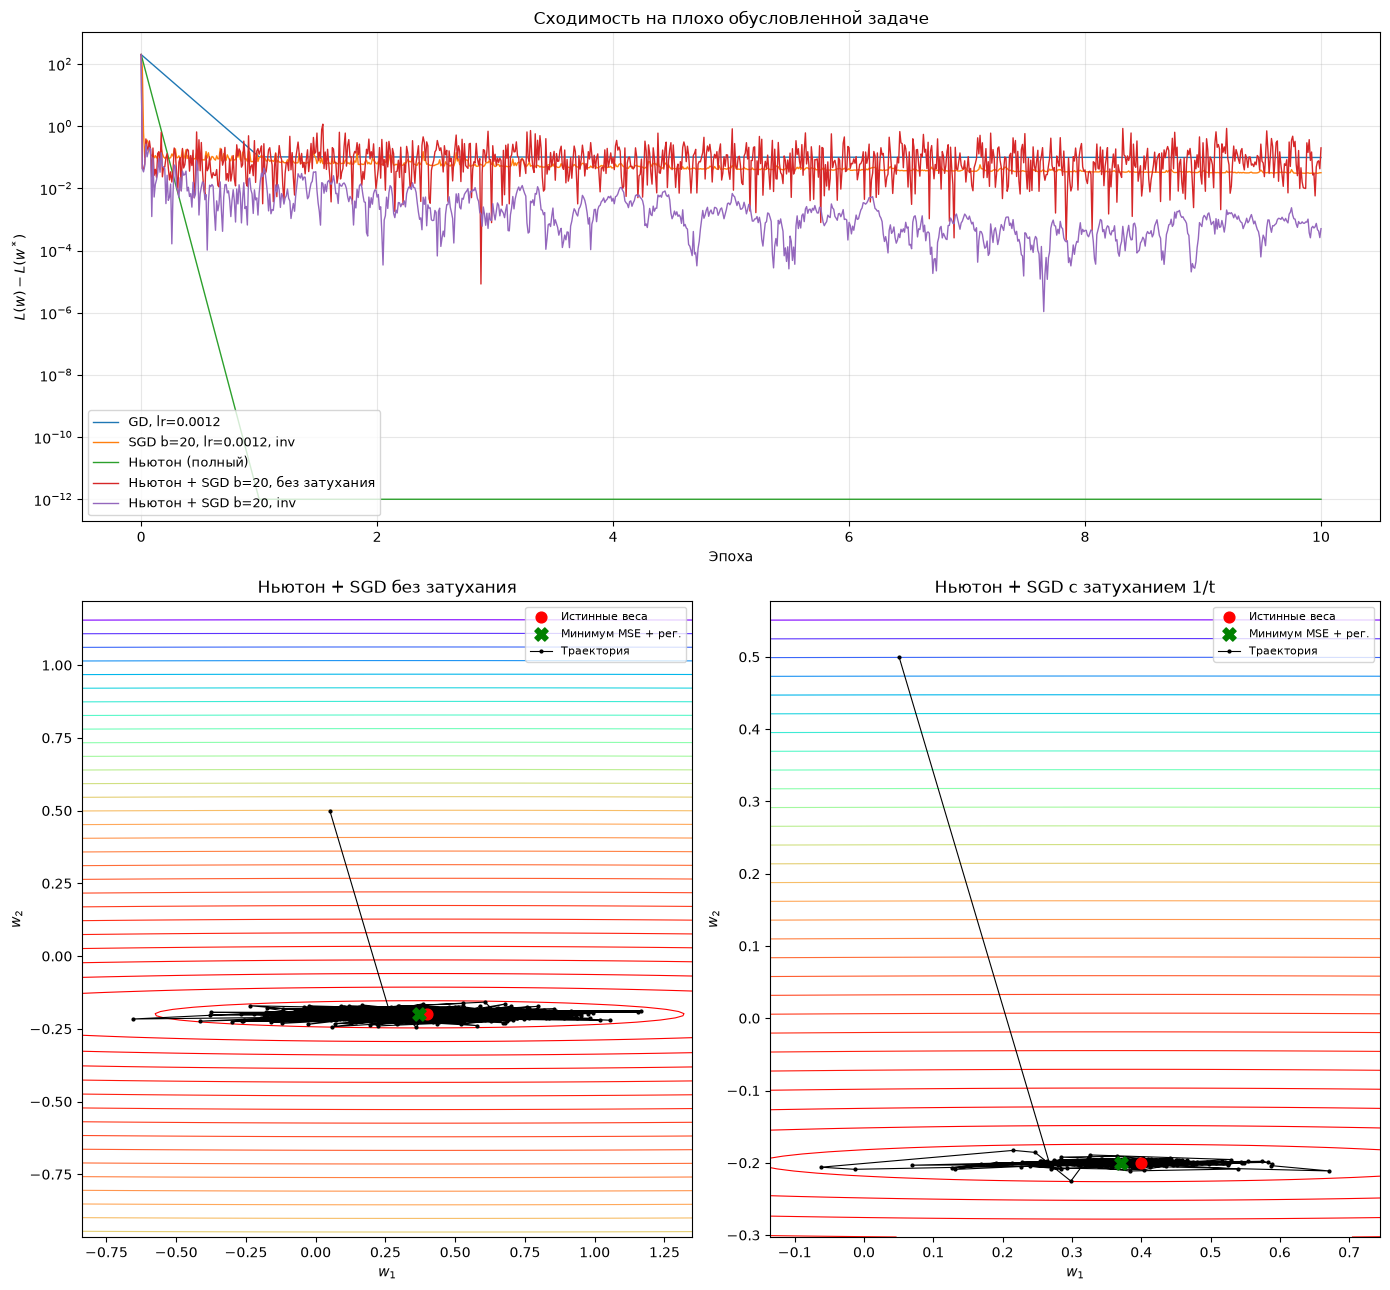

GD, lr=0.0012                            ||w - w*|| = 3.14e-01   L - L* = 9.88e-02
SGD b=20, lr=0.0012, inv                 ||w - w*|| = 1.75e-01   L - L* = 3.19e-02
Ньютон (полный)                          ||w - w*|| = 1.86e-16   L - L* = 0.00e+00
Ньютон + SGD b=20, без затухания         ||w - w*|| = 4.17e-01   L - L* = 2.01e-01
Ньютон + SGD b=20, inv                   ||w - w*|| = 2.20e-02   L - L* = 5.06e-04


In [18]:
np.random.seed(51)
n5 = 2000
X5 = np.concatenate([np.random.normal(0, 1, (n5, 1)), np.random.normal(0, 20, (n5, 1))], axis=1)
w_true5 = np.array([[0.4], [-0.2]])
y5 = X5 @ w_true5 + np.random.normal(0, 1, (n5, 1))
w_exact5 = np.linalg.solve(X5.T @ X5 + n5 * 0.001 * np.eye(2), X5.T @ y5)  # точное Ridge-решение для alpha=0.001
L_opt5 = Regressor(regularization="L2", alpha=0.001).total_loss(X5, y5, w_exact5)

lam = np.linalg.eigvalsh(Regressor(regularization="L2", alpha=0.001).hessian(X5, y5, w_true5))
lr5 = 1 / lam.max()
print(f"Собственные числа гессиана: {lam.round(2)}, число обусловленности = {lam.max() / lam.min():.0f}")
print(f"GD устойчив при lr < 2/lambda_max = {2 / lam.max():.4f}; беру lr = 1/lambda_max = {lr5:.4f}")
RESULTS["hess_eig"] = lam.tolist()
runs5 = {
    f"GD, lr={lr5:.4f}":                   dict(lr=lr5, epochs=10),
    f"SGD b=20, lr={lr5:.4f}, inv":        dict(lr=lr5, epochs=10, batch_size=20, lr_decay="inv", decay_rate=0.01),
    "Ньютон (полный)":                     dict(epochs=10, use_newton=True),
    "Ньютон + SGD b=20, без затухания":    dict(epochs=10, use_newton=True, batch_size=20),
    "Ньютон + SGD b=20, inv":              dict(epochs=10, use_newton=True, batch_size=20, lr_decay="inv", decay_rate=0.05),
}
fitted5 = {}
for name, kw in runs5.items():
    np.random.seed(4)
    fitted5[name] = Regressor(regularization="L2", alpha=0.001, **kw).fit(X5, y5)

fig, axes = plt.subplot_mosaic([["loss", "loss"], ["t1", "t2"]], figsize=(14, 13), height_ratios=[1, 1.3])
for name, m in fitted5.items():
    steps = np.arange(len(m.loss_history))
    per_epoch = max(1, (len(m.loss_history) - 1) // m.epochs)
    axes["loss"].plot(steps / per_epoch, np.maximum(np.array(m.loss_history) - L_opt5, 1e-12), lw=1, label=name)
axes["loss"].set_yscale("log"); axes["loss"].set_xlabel("Эпоха"); axes["loss"].set_ylabel("$L(w)-L(w^*)$")
axes["loss"].set_title("Сходимость на плохо обусловленной задаче"); axes["loss"].legend(fontsize=9); axes["loss"].grid(alpha=0.3, which="both")
fitted5["Ньютон + SGD b=20, без затухания"].show_training(w_true5, X5, y5, ax=axes["t1"], title="Ньютон + SGD без затухания", show_reg=False)
fitted5["Ньютон + SGD b=20, inv"].show_training(w_true5, X5, y5, ax=axes["t2"], title="Ньютон + SGD с затуханием 1/t", show_reg=False)
for k in ("t1", "t2"):
    axes[k].set_aspect("auto")
fig.tight_layout(); fig.savefig("figures/newton_sgd.png", dpi=130, bbox_inches="tight"); plt.show()

ns_table = []
for name, m in fitted5.items():
    ns_table.append([name, float(np.linalg.norm(m.w - w_exact5)), float(m.loss_history[-1] - L_opt5)])
    print(f"{name:40s} ||w - w*|| = {np.linalg.norm(m.w - w_exact5):.2e}   L - L* = {m.loss_history[-1] - L_opt5:.2e}")
RESULTS["newton_sgd_table"] = ns_table

with open("figures/results.json", "w") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2, default=float)

**Как работает Ньютон вместе с SGD.**
- Полный метод Ньютона сходится за один шаг независимо от масштаба признаков — гессиан «выравнивает» вытянутый параболоид. Обычному GD на этой задаче приходится брать `lr` меньше $2/\lambda_{max}$ (иначе он расходится по «крутому» направлению $w_2$), и по «пологому» направлению $w_1$, где собственное число в сотни раз меньше, он ползёт очень медленно.
- Ньютон на мини-батчах без затухания ведёт себя плохо: каждый шаг переносит веса в минимум ошибки *по текущему батчу* (по сути МНК по 20 точкам), поэтому веса не сходятся, а прыгают вокруг решения с разбросом, соответствующим размеру батча. Ошибка застревает на уровне «шума батча».
- Если уменьшать шаг Ньютона ($w \leftarrow w - \eta_t H_b^{-1}g_b$ с $\eta_t\to0$), метод начинает сходиться и при этом не чувствителен к масштабу признаков: каждый шаг усредняет решения по батчам. Это идея стохастических квазиньютоновских методов. Но для больших моделей это всё равно непрактично — гессиан $d\times d$ и его обращение стоят $O(d^3)$.